# 17-FreeRTOS移植到平衡球项目实战


## 1. 项目定位与资料说明

本篇是17篇RTOS笔记的最后一篇，把前面学过的任务、调度、中断、内存和通信机制串成一条项目移植路线。

**资料范围：**已确认课程目录存在 `code/code.zip` 和 `video/21.freeRTOS移植到平衡球项目中.mp4`，该视频页面显示时长28:04、分享试看90秒。本轮尝试普通下载后未取得源码包，未完成视频全文阅读或转录。没有独立对应PPT。因此本篇是依据课程介绍与前16篇知识整理的**项目移植补充笔记**，不是最后一节视频的逐步复现；任务拆分、接口和代码均为说明性方案。

可以核实的是课程以平衡球项目为最终对象，展示了装置和包含 `Kp`、`Ki`、`Kd` 的界面。具体工程目录、芯片型号、传感器类型、执行机构、引脚、原函数名、原始周期和老师最终任务配置尚未确认。

学习目标是能够解释：怎样保留已有控制逻辑，引入FreeRTOS；怎样安排控制与界面等工作；怎样在任务间传递参数和状态；怎样检查控制周期、资源竞争和工程移植故障。未进行开发板编译、下载或运行验证。


## 2. 平衡球项目背景与控制链路

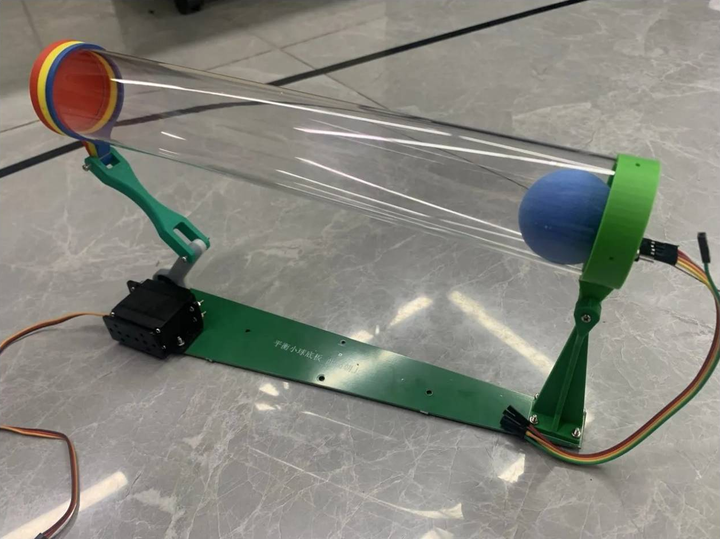

*来源：`01课程介绍.pptx` 第6页，复用第01篇保存的课件实物图。图片只用于说明课程项目对象。*

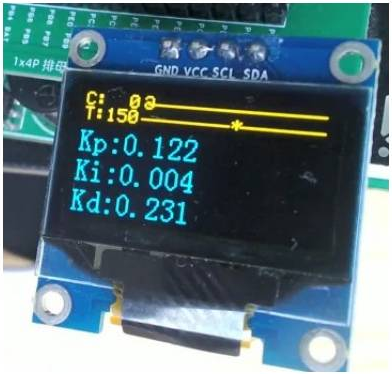

*来源：`01课程介绍.pptx` 第7页。显示的参数值不是本篇推荐或实测值。*

从一般反馈控制的角度，可以把项目理解为以下处理链；这是讲解模型，具体测量与输出方式以项目源码为准。

```text
读取当前状态 → 与目标状态比较 → 控制算法计算 → 限制输出 → 更新执行输出
       ↑                                              │
       └──────────── 下一次测量反映作用结果 ────────────┘
```

RTOS负责组织这些处理的执行时机、响应顺序与数据协作。控制算法、测量标定和执行输出仍然需要应用实现。移植时首先关注原控制链是否保持完整，再关注各项辅助工作能否在不影响控制的条件下推进。

例如，若显示刷新很慢，把刷新放进控制循环就会拉长采样间隔。拆分后，控制任务发布状态快照，显示任务按自己的刷新节奏读取，界面耗时不再直接决定控制循环的周期。但共享总线仍可能造成间接阻塞，需要单独设计。


## 3. 移植前：先梳理裸机工程

打开原工程后，先建立功能和时序清单，避免把全部主循环机械地包进一个任务。

| 阅读位置 | 需要记录的内容 | 对移植的影响 |
|---|---|---|
| 启动文件与工程设置 | 内核架构、编译器、启动入口、中断向量 | 决定使用哪个FreeRTOS移植层 |
| 主函数与主循环 | 初始化顺序、各函数调用次序 | 确定任务边界与依赖 |
| 控制算法 | 状态变量、积分累计、微分计算、时间基准 | 判断周期变化是否影响参数含义 |
| 定时器与中断 | 周期、中断优先级、哪些工作在ISR执行 | 避免Tick或控制触发源冲突 |
| 驱动与延时函数 | 忙等待、超时、共享总线、DMA或中断依赖 | 判断能否在任务中阻塞以及驱动是否可重入 |
| 参数与显示逻辑 | 谁修改参数、谁读取状态、缓冲区归属 | 确定通信机制与所有权 |

原有控制可能位于主循环，也可能位于定时器中断。先确认真正的控制入口，再选择保留中断控制、周期任务控制或定时器通知任务控制的方式。不要保留原中断计算的同时，在任务里再次执行同一控制算法。

保存一份裸机基线，记录构建结果和实际运行现象。比较移植前后的行为时，先固定算法、参数和输入条件；同时修改调度和PID参数会让问题来源难以判断。


## 4. FreeRTOS工程接入与时钟配置

具体接入操作可回看第02、03篇。本节按项目检查项组织：

1. 根据实际处理器、编译器和浮点配置选择匹配的 `portable` 移植目录，只保留所需端口。
2. 加入内核源文件和头文件搜索路径；按使用功能加入 `queue.c`、`event_groups.c`、`timers.c` 等源文件。
3. 动态分配方案只选择一个适用的 `heap_x.c`；静态方案则提供应用需要的静态存储及对应回调。
4. 配置 `FreeRTOSConfig.h` 中的时钟、Tick、优先级数量、内存和功能开关。
5. 检查启动向量、异常处理函数与移植层要求的一致性。Cortex-M端口通常涉及SVC、PendSV和SysTick；具体符号接法按所选端口处理。
6. 先验证最小任务的周期运行和阻塞，再加入项目控制逻辑。

原工程若已经使用SysTick，不能让原处理函数和RTOS处理函数各自占用同一个异常入口。应按端口要求确定内核Tick来源，再给原应用时基选择独立定时器或兼容的实现。不要将毫秒忙等待代码未经检查就改成依赖调度器的延时，初始化阶段可能尚未启动调度。

`configTICK_RATE_HZ` 决定任务延时的Tick粒度，并不等于控制频率。较高Tick频率会增加中断开销；如果控制时序精度不足，应评估硬件定时器触发方案，而不是无条件提高Tick频率。

浮点运算还需要匹配处理器FPU能力、编译选项与端口支持；PID是否使用浮点，以及上下文切换成本，均需从实际工程确认。


## 5. 任务拆分：按职责与时序需求组织

下面是一种用于理解项目的拆分方案，**不是课程已核实的任务清单**。初次移植可把测量、计算和执行更新留在同一控制任务内，减少中间数据同步和时序变化。

| 逻辑职责 | 建议执行方式 | 数据输入与输出 | 设计重点 |
|---|---|---|---|
| 控制链路 | 周期任务或定时器通知任务 | 测量值、参数 → 执行输出、状态快照 | 周期、数据新鲜度和最坏耗时 |
| 参数输入 | 按键扫描或命令解析任务 | 输入事件 → 完整参数命令 | 消抖、合法性检查、队列满策略 |
| 界面显示 | 较低优先级任务 | 状态快照 → 界面 | 刷新降频，避免占用控制时间 |
| 日志输出 | 低优先级任务，可选 | 诊断消息 → 输出设备 | 输出拥塞时不阻塞控制 |
| 初始化 | main中完成或专用启动任务 | 初始化结果 → 就绪状态 | 控制开始前驱动与通信对象已准备 |

如果采样与输出属于严格同步链路，先保持它们在一起。只有确认采样为独立异步源、需要由中断或DMA发布数据时，再考虑拆出采样任务。

任务数越多，任务栈、通信对象和切换开销越大。选择边界时，需要回答“这项工作是否有不同的周期、不同的阻塞原因或独立的数据所有权”，而不是按每个函数创建一个任务。


## 6. 控制周期与优先级设计

`vTaskDelay()` 从调用时刻开始等待，相邻循环间隔通常包含处理耗时和等待时间。固定周期任务可采用 `vTaskDelayUntil()`，围绕上一次计划唤醒时刻递推；它不能消除中断、高优先级任务或共享资源导致的延迟。

```c
/* 说明性片段：应用定义CONTROL_PERIOD_MS和ControlStep。 */
static void ControlTask(void *arg)
{
    (void)arg;
    const TickType_t period = pdMS_TO_TICKS(CONTROL_PERIOD_MS);
    configASSERT(period > 0);
    TickType_t release = xTaskGetTickCount();

    for (;;) {
        ControlStep();  /* 读取、计算、限幅和输出；实现必须有界。 */
        vTaskDelayUntil(&release, period);
    }
}
```

片段假设该内核启用了对应API。周期宏没有给出数值，因为原项目周期尚未确认。毫秒到Tick的转换可能截断，周期小于一个Tick时需要改变配置或使用其他触发方式。

运行超出计划周期时，延时可能不再阻塞，并可能连续运行若干次以追赶计划；要统计超期次数，明确采用追赶、跳过过期周期或重新设定相位的策略，不能默认“调用了周期延时就满足实时性”。

控制任务通常应比显示与日志更紧急，但优先级要基于截止时间与依赖关系确定。FreeRTOS任务优先级数值较大通常表示更高；Cortex-M中断优先级编码规则不同，不要混用这两种概念。

应测量控制处理耗时、被抢占时间、资源等待时间和实际唤醒抖动。一个任务自身耗时小于周期，只是满足时序的必要条件之一。


## 7. PID与任务周期变化的关系

课程界面中的 `Kp`、`Ki`、`Kd` 说明项目涉及控制参数。以下公式用于说明周期影响，**不代表原项目的PID实现**。

一种离散表达为：

```text
e[k] = 目标值 - 测量值
I[k] = I[k-1] + e[k] × Δt
D[k] = (e[k] - e[k-1]) / Δt
u[k] = Kp × e[k] + Ki × I[k] + Kd × D[k]
```

有些程序把采样周期吸收到离散系数中，不在每次计算时显式乘除Δt。此时改变调用周期会改变积分与微分的实际作用。移植前应先确认系数定义，保持原控制周期和状态更新顺序，再讨论调参。

还需要关注输出限幅、积分饱和、微分噪声和状态复位：停止控制时是否继续累计积分；重新启动时是否清除历史误差；参数切换是否需要平滑处理；测量失效时输出如何进入项目定义的受限状态。

固定周期唤醒也不保证测量是新的。读取失败或得到旧样本时，不能未经设计继续更新积分。可在状态中携带采样序号、采样时间和有效标志，明确允许的数据年龄及超时处理。


## 8. 参数与状态：用数据所有权减少竞争

建议由控制任务独占PID内部状态及执行输出。输入任务只提交参数命令，显示任务只读取状态快照。这样辅助任务无需直接修改积分累计、历史误差或输出寄存器。

| 数据路径 | 可选机制 | 关键约定 |
|---|---|---|
| 输入 → 控制 | 结构体消息队列 | 按顺序消费，明确满队列时拒绝或合并命令 |
| 控制 → 显示 | 长度为1的最新状态队列 | 允许覆盖旧快照，只保证最新状态 |
| ISR → 控制 | 二值信号量或任务通知 | 通知是否合并、是否累计以及ISR优先级 |
| 多初始化条件 → 控制 | 事件组 | 条件满足后再开始，事件位不承载参数值 |
| 多任务共享驱动 | Mutex或单一驱动任务 | 串行访问和可接受的阻塞上限 |

```c
/* 说明性数据结构，并非课程原结构体。 */
typedef struct {
    float kp, ki, kd;
    uint32_t version;
} ControlParams;

typedef struct {
    float measurement;
    float output;
    uint32_t sequence;
    TickType_t sample_tick;
    BaseType_t valid;
} ControlSnapshot;
```

参数应作为完整结构体传递，在同一控制周期边界统一接收和应用，避免读取到“新Kp、旧Ki、旧Kd”的混合配置。接收端仍需检查数值范围与NaN等非法输入。

队列复制的是队列项本身；若项中保存指针，指向的内存不会被复制。这里采用值结构体以避免栈上临时缓冲区失效。显示、记录日志若都需要同一快照，不能简单让两个接收者竞争同一个队列并假设各自都会收到，可分别建立最新值队列。


## 9. 控制与显示协作的说明性框架

下面省略原工程中尚未确认的驱动和算法实现，只展示通信顺序。全局句柄必须在启动任务前创建成功；任务栈、优先级和周期由工程测量后配置。

```c
/* 需包含FreeRTOS.h、task.h和queue.h。
 * 控制周期、应用接口及结构体由工程提供；此段不能直接替代完整工程。
 */
static QueueHandle_t params_queue;
static QueueHandle_t display_queue;

static void ProjectControlTask(void *arg)
{
    (void)arg;
    ControlParams active = AppInitialParams();
    ControlParams next;
    ControlSnapshot state;
    const TickType_t period = pdMS_TO_TICKS(CONTROL_PERIOD_MS);
    configASSERT(period > 0);
    TickType_t release = xTaskGetTickCount();

    for (;;) {
        /* 每周期最多消费一条，防止命令突发挤占控制时间。 */
        if (xQueueReceive(params_queue, &next, 0) == pdPASS) {
            if (AppParamsValid(&next)) {
                active = next;
            }
        }

        state = AppControlStep(&active);
        /* AppControlStep负责样本有效性、控制计算、输出限制及故障处理。 */
        (void)xQueueOverwrite(display_queue, &state);
        vTaskDelayUntil(&release, period);
    }
}

static void ProjectDisplayTask(void *arg)
{
    (void)arg;
    ControlSnapshot state;
    const TickType_t refresh = pdMS_TO_TICKS(DISPLAY_REFRESH_MS);
    configASSERT(refresh > 0);

    for (;;) {
        if (xQueueReceive(display_queue, &state, portMAX_DELAY) == pdPASS) {
            AppDrawSnapshot(&state);
        }
        vTaskDelay(refresh);
    }
}
```

`display_queue` 必须通过 `xQueueCreate(1, sizeof(ControlSnapshot))` 创建；`xQueueOverwrite()`用于长度为1的队列。控制任务不等待显示接收，显示忙时旧快照会被最新快照覆盖。

参数队列采用有限容量，输入端发送失败必须反馈或记录，不能悄悄丢弃关键命令。每周期最多处理一条便于控制耗时，但会增加命令积压延迟；若只关心最终参数，可另行设计最新值覆盖策略。紧急停止不应排在大量普通调参命令之后，需要独立响应设计。

示例没有初始化代码、任务创建代码及应用函数定义，也未测试控制效果。`portMAX_DELAY`的无限等待语义需要匹配内核配置。两个控制任务示例分别说明周期和通信，工程中应选择一个实际控制入口。


## 10. 中断与共享外设的边界

若硬件定时器提供控制触发，中断宜完成短小的确认与通知，由任务执行较长的应用逻辑。下面演示二值信号量唤醒方式，不指定具体定时器或板级函数名。

```c
/* 说明性ISR片段：入口与清标志代码按实际硬件补齐。 */
BaseType_t higher_priority_woken = pdFALSE;
xSemaphoreGiveFromISR(control_ready, &higher_priority_woken);
portYIELD_FROM_ISR(higher_priority_woken);
```

要求ISR使用端口允许调用FreeRTOS API的中断优先级，信号量已经创建，且调度器启动顺序正确。具体换出宏按端口定义处理。ISR不能获取Mutex，不能调用任务版阻塞API。

二值信号量最多保留一个待处理许可；任务未处理完时发生多次触发会合并。计数信号量或计数型通知可保留次数，但“补算多次”并不自动补回丢失的传感器数据。应选择是否按最新样本运行，并记录触发丢失或积压。

控制和显示如果共享I²C、SPI或驱动缓冲区，应分析完整事务。Mutex可避免同时操作，但高优先级控制仍会等待低优先级显示结束当前事务。优先级继承不能缩短已经开始的长事务，因此还需缩短显示事务、分批刷新、使用独立外设或设置驱动所有者。

临界区只用于极短且不阻塞的更新。不能把整屏刷新、串口长输出或等待DMA完成放入长临界区。软件定时器回调也应短小，可发通知给任务，不宜直接承载较长控制流程。


## 11. 启动、内存与故障处理

推荐先完成时钟与必要驱动初始化，创建通信对象并检查结果，创建任务并检查返回值，最后启动调度器。需要中断发布数据的驱动，在队列/信号量和接收任务就绪之前不能向未初始化对象发通知。

如果初始化放在任务中，其他任务必须等待明确的完成状态。启动任务完成后可删除自身，但传给其他任务的参数与缓冲区必须仍然有效，不能保存在被删除任务的局部栈内。

| 检查项 | 工程中要做的事 |
|---|---|
| 动态创建 | 检查队列、Mutex与任务创建返回值；失败时停止启动控制 |
| 静态创建 | 保证TCB、队列存储区和栈拥有足够容量及正确生命周期 |
| 任务栈 | 根据调用深度、格式化输出和浮点库测量余量；创建API的栈深度通常以StackType_t项数表示 |
| 内核堆 | 统计任务、队列和内核对象的分配，保留必要余量 |
| 调试钩子 | 按配置启用断言、栈溢出检测和分配失败处理 |
| 应用故障 | 定义测量超时、输出异常、命令非法和控制超期时的行为 |

`uxTaskGetStackHighWaterMark()`等工具可以帮助观察历史栈余量，但一次运行未触及最坏路径，不代表栈永远足够。调试输出也会改变时间和栈消耗，应使用有界记录或低优先级日志任务。

`vTaskStartScheduler()`意外返回时应进入工程定义的启动失败处理。很多端口中，这与Idle任务等内核任务创建失败有关，需要检查堆与相关配置，而不能接着运行旧主循环并假装调度器已启动。


## 12. 分阶段验证与常见问题

以下是待在真实工程和开发板执行的验证方案，不是本轮已完成的测试。

| 阶段 | 验证内容 | 应记录的证据 |
|---|---|---|
| 裸机基线 | 原工程能构建，原控制周期和输入输出关系明确 | 工程版本、周期测量和运行现象 |
| 最小RTOS | 最小任务能够运行、延时阻塞，中断入口正确 | 调试观察与周期记录 |
| 控制链恢复 | 保持原算法、原参数、原测量与输出流程 | 实际采样间隔、输出变化和异常计数 |
| 加入辅助任务 | 显示、输入、日志同时运行 | 控制抖动、队列积压、总线等待 |
| 压力与故障 | 密集调参、显示持续刷新、测量超时、队列满 | 处理策略是否执行、是否恢复正常 |
| 长时间运行 | 堆与栈余量、任务活性和数据新鲜度 | 最大耗时、最大抖动、超期次数 |

常见现象与排查方向：

- **任务只执行一次：**检查Tick中断、优先级、无限忙循环及是否真正进入调度。
- **加入显示后控制不稳：**检查总线占用、驱动锁、长临界区和刷新事务；再检查共享数据。
- **移植后相同PID参数效果不同：**核对实际采样周期、离散系数含义、样本年龄及重复控制调用。
- **参数偶尔出现异常：**检查多任务直接写同一结构体、队列项大小、指针生命周期和合法性校验。
- **开启中断后断言失败：**核对FromISR接口、NVIC优先级分组、优先级编码和允许调用API的范围。
- **偶发HardFault：**检查栈溢出、失效指针、句柄创建失败、移植层与浮点配置，以及异常堆栈。

运行记录至少应包含工程版本、控制周期目标、实际周期范围、控制耗时、栈余量和故障计数。界面持续刷新只能证明界面任务在推进，不能单独证明闭环时序和控制效果正确。


## 13. 本篇复习与课程串联

完成项目移植时，应能讲清楚一条完整链路：启动准备驱动和内核对象；控制入口按规定节奏读取有效测量并更新输出；输入任务提交完整命令；显示任务消费状态快照；资源访问有明确所有者；异常被记录并按预定策略处理。

| 相关笔记 | 在项目中的应用 |
|---|---|
| 02—03 环境与移植 | 端口、时钟、异常入口和最小多任务验证 |
| 04—06 任务与调度 | 任务创建、优先级、状态、栈和周期 |
| 07—09 资源、内存和中断 | 保护共享状态、对象容量、ISR调用边界 |
| 10 软件定时器 | 轻量维护和通知，回调避免长时间阻塞 |
| 11—14 通信与信号量 | 区分唤醒、计数及外设所有权 |
| 15 消息队列 | 参数命令和完整状态快照 |
| 16 事件组 | 多条件就绪和启动同步 |

复习时回答这几个问题：控制周期由谁产生？参数在什么时刻生效？显示变慢会阻塞控制吗？重复中断是否合并？样本过期时输出怎样处理？创建对象失败时系统是否仍会启动控制？

**待补齐的课程细节：**取得 `code.zip` 与最后一节视频后，需要核实实际工程目录、控制入口、真实任务列表、周期与优先级、驱动接口、Tick适配方式及老师演示的验证结果。本篇没有把这些未知项填成假定值；现有内容可用于理解与准备移植，不能作为课程原工程已经复现的证明。
